In [1]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

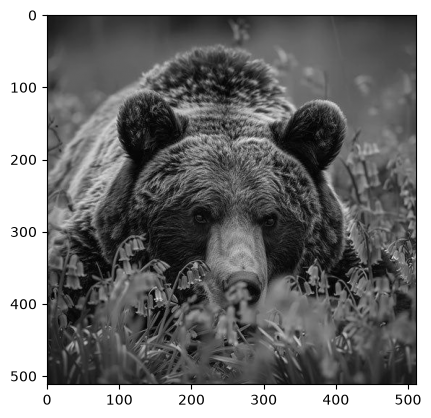

In [2]:
img = cv.imread('bear.jpg', cv.IMREAD_GRAYSCALE)
plt.imshow(img, cmap = 'gray')

In [11]:
def haar_step(img):
    img = np.asarray(img, dtype=np.float64)
    L = (img[:, 0::2] + img[:, 1::2]) / 2.0
    H = (img[:, 0::2] - img[:, 1::2]) / 2.0
    LL = (L[0::2, :] + L[1::2, :]) / 2.0
    LH = (L[0::2, :] - L[1::2, :]) / 2.0
    HL = (H[0::2, :] + H[1::2, :]) / 2.0
    HH = (H[0::2, :] - H[1::2, :]) / 2.0
    return LL, LH, HL, HH

In [12]:
def normalize(arr):
    arr_min, arr_max = arr.min(), arr.max()
    if arr_max - arr_min < 1e-8:
        return np.zeros_like(arr, dtype=np.uint8)
    return np.uint8((arr - arr_min) / (arr_max - arr_min) * 255)

In [13]:
LL1, LH1, HL1, HH1 = haar_step(img)  # 256
LL2, LH2, HL2, HH2 = haar_step(LL1)  # 128
LL3, LH3, HL3, HH3 = haar_step(LL2)  # 64

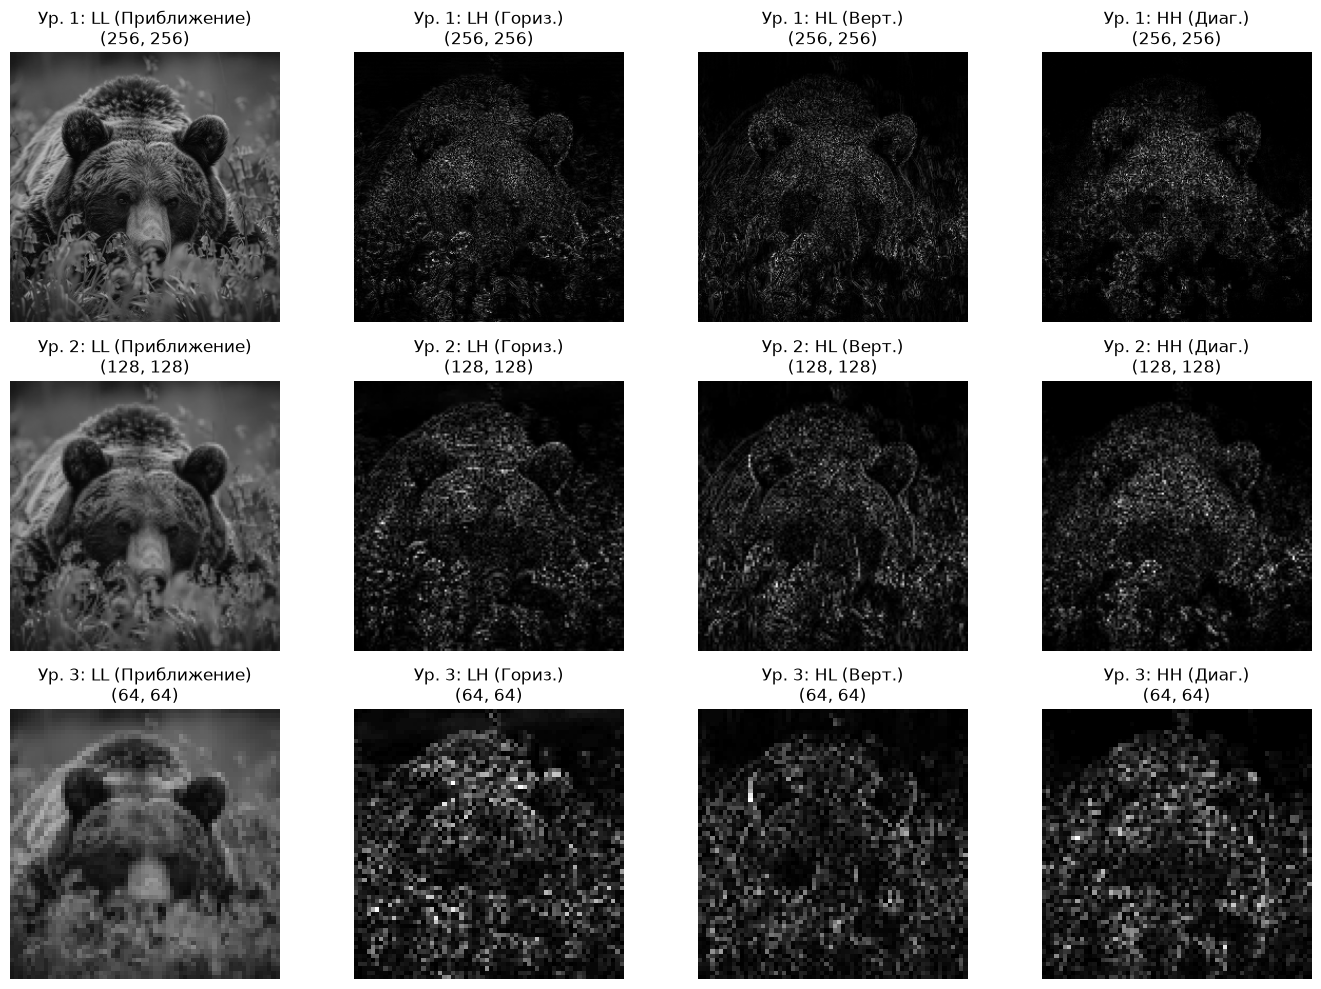

In [14]:
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
levels = [(LL1, LH1, HL1, HH1), (LL2, LH2, HL2, HH2), (LL3, LH3, HL3, HH3)]
names = ['LL (Приближение)', 'LH (Гориз.)', 'HL (Верт.)', 'HH (Диаг.)']

for row, (level, lvl_num) in enumerate(zip(levels, [1, 2, 3])):
    for col, (comp, name) in enumerate(zip(level, names)):
        ax = axes[row, col]

        if col == 0:
            vis = np.clip(comp, 0, 255).astype(np.uint8)
        else:
            vis = normalize(np.abs(comp))

        ax.imshow(vis, cmap='gray', vmin=0, vmax=255)
        ax.set_title(f'Ур. {lvl_num}: {name}\n{comp.shape}')
        ax.axis('off')

plt.tight_layout()
plt.show()